# Homework 7

Name: Xiaoyi Kuang  
GitHub username: Xiaoyi-Kuang1

## 1.
### (a)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, f1_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
data = pd.read_csv(Path('../data/Frogs_MFCCs.csv'))
labels = ['Family', 'Genus', 'Species']
x = data.drop(columns=labels + ['RecordID'])
y = data[labels]
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.7, random_state=1)
print('Training rows:', len(x_train))
print('Test rows:', len(x_test))
print('Features:', x.shape[1])

Training rows: 5036
Test rows: 2159
Features: 22


### (b)(i)

Exact match is the fraction of rows with all three labels correct. Hamming loss is the fraction of individual labels predicted incorrectly. Hamming score is 1 minus Hamming loss. Average Hamming distance is the mean number of wrong labels per row, from 0 to 3.

In [2]:
def evaluate(actual, predicted):
    correct = np.asarray(actual) == np.asarray(predicted)
    return [correct.all(axis=1).mean(), correct.mean(), 1 - correct.mean()]

scores = []
folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)
c_values = [0.01, 0.1, 1, 10, 100, 1000]

### (b)(ii)

In [3]:
rbf_train = pd.DataFrame(index=y_train.index)
rbf_test = pd.DataFrame(index=y_test.index)
rbf_rows = []
sigma_values = np.arange(1, 21) / 10
gamma_values = 1 / (2 * sigma_values ** 2)
for name in labels:
    model = OneVsRestClassifier(SVC(kernel='rbf'))
    params = {'estimator__C': c_values, 'estimator__gamma': gamma_values}
    search = GridSearchCV(model, params, cv=folds, scoring='accuracy', n_jobs=4)
    search.fit(x_train, y_train[name])
    best = search.best_estimator_
    rbf_train[name] = best.predict(x_train)
    rbf_test[name] = best.predict(x_test)
    best_c = search.best_params_['estimator__C']
    best_gamma = search.best_params_['estimator__gamma']
    rbf_rows.append([name, best_c, best_gamma, np.sqrt(1 / (2 * best_gamma)), search.best_score_])
display(pd.DataFrame(rbf_rows, columns=['Label', 'C', 'gamma', 'sigma', 'CV accuracy']))
for name, actual, predicted in [('Train', y_train, rbf_train), ('Test', y_test, rbf_test)]:
    scores.append(['Gaussian SVM', name] + evaluate(actual, predicted))
display(pd.DataFrame(scores, columns=['Model', 'Set', 'Exact match', 'Hamming score', 'Hamming loss']).round(4))

,Label,C,gamma,sigma,CV accuracy
0,Family,10,3.125,0.4,0.992654
1,Genus,100,3.125,0.4,0.990863
2,Species,100,3.125,0.4,0.991262


,Model,Set,Exact match,Hamming score,Hamming loss
0,Gaussian SVM,Train,1.000,1.00,0.00
1,Gaussian SVM,Test,0.987,0.99,0.01


### (b)(iii)

In [4]:
linear_c_values = c_values + [10000]
linear_train = pd.DataFrame(index=y_train.index)
linear_test = pd.DataFrame(index=y_test.index)
linear_rows = []
for name in labels:
    model = Pipeline([('scale', StandardScaler()), ('svm', LinearSVC(penalty='l1', dual=False, max_iter=100000, random_state=1))])
    search = GridSearchCV(model, {'svm__C': linear_c_values}, cv=folds, scoring='accuracy', n_jobs=4)
    search.fit(x_train, y_train[name])
    linear_train[name] = search.predict(x_train)
    linear_test[name] = search.predict(x_test)
    linear_rows.append([name, search.best_params_['svm__C'], search.best_score_])
display(pd.DataFrame(linear_rows, columns=['Label', 'C', 'CV accuracy']))
for name, actual, predicted in [('Train', y_train, linear_train), ('Test', y_test, linear_test)]:
    scores.append(['L1 SVM', name] + evaluate(actual, predicted))
display(pd.DataFrame(scores[-2:], columns=['Model', 'Set', 'Exact match', 'Hamming score', 'Hamming loss']).round(4))

,Label,C,CV accuracy
0,Family,1,0.938048
1,Genus,1000,0.956310
2,Species,1,0.959497


,Model,Set,Exact match,Hamming score,Hamming loss
0,L1 SVM,Train,0.9241,0.9543,0.0457
1,L1 SVM,Test,0.9134,0.9455,0.0545


### (b)(iv)

In [5]:
counts = []
for name in labels:
    for group, count in y_train[name].value_counts().items():
        counts.append([name, group, count])
display(pd.DataFrame(counts, columns=['Label', 'Class', 'Training count']))

balanced_train = pd.DataFrame(index=y_train.index)
balanced_test = pd.DataFrame(index=y_test.index)
balanced_rows = []
for name in labels:
    model = Pipeline([('scale', StandardScaler()), ('svm', LinearSVC(penalty='l1', dual=False, class_weight='balanced', max_iter=100000, random_state=1))])
    search = GridSearchCV(model, {'svm__C': linear_c_values}, cv=folds, scoring='accuracy', n_jobs=4)
    search.fit(x_train, y_train[name])
    balanced_train[name] = search.predict(x_train)
    balanced_test[name] = search.predict(x_test)
    balanced_rows.append([name, search.best_params_['svm__C'], search.best_score_])
display(pd.DataFrame(balanced_rows, columns=['Label', 'C', 'CV accuracy']))
for name, actual, predicted in [('Train', y_train, balanced_train), ('Test', y_test, balanced_test)]:
    scores.append(['Balanced L1 SVM', name] + evaluate(actual, predicted))
results = pd.DataFrame(scores, columns=['Model', 'Set', 'Exact match', 'Hamming score', 'Hamming loss'])
display(results.round(4))

f1_rows = []
for model, predicted in [('Gaussian SVM', rbf_test), ('L1 SVM', linear_test), ('Balanced L1 SVM', balanced_test)]:
    for name in labels:
        f1_rows.append([model, name, f1_score(y_test[name], predicted[name], average='macro')])
f1_results = pd.DataFrame(f1_rows, columns=['Model', 'Label', 'Test macro-F1'])
display(f1_results.round(4))

,Label,Class,Training count
0,Family,Leptodactylidae,3092
1,Family,Hylidae,1509
2,Family,Dendrobatidae,387
3,Family,Bufonidae,48
4,Genus,Adenomera,2891
5,Genus,Hypsiboas,1111
6,Genus,Ameerega,387
7,Genus,Dendropsophus,209
8,Genus,Leptodactylus,201
9,Genus,Scinax,109


,Label,C,CV accuracy
0,Family,10,0.937454
1,Genus,100,0.952338
2,Species,10,0.961680


,Model,Set,Exact match,Hamming score,Hamming loss
0,Gaussian SVM,Train,1.0000,1.0000,0.0000
1,Gaussian SVM,Test,0.9870,0.9900,0.0100
2,L1 SVM,Train,0.9241,0.9543,0.0457
3,L1 SVM,Test,0.9134,0.9455,0.0545
4,Balanced L1 SVM,Train,0.9202,0.9541,0.0459
5,Balanced L1 SVM,Test,0.9083,0.9443,0.0557


,Model,Label,Test macro-F1
0,Gaussian SVM,Family,0.9547
1,Gaussian SVM,Genus,0.9552
2,Gaussian SVM,Species,0.9664
3,L1 SVM,Family,0.6832
4,L1 SVM,Genus,0.8488
5,L1 SVM,Species,0.8894
6,Balanced L1 SVM,Family,0.8122
7,Balanced L1 SVM,Genus,0.8486
8,Balanced L1 SVM,Species,0.8762


The Gaussian SVM performs best on this split. Its test exact match is 0.9870, its Hamming loss is 0.0100, and its macro-F1 is above 0.95 for all three labels. The training exact match is 1.0000, but the gap to the test result is small. I think the Gaussian kernel helps because it can fit nonlinear patterns, while the L1 SVM is linear. Class weighting helps in some places but not others. Family macro-F1 rises from 0.6832 to 0.8122, but test exact match drops from 0.9134 to 0.9083. Genus macro-F1 barely changes, and Species macro-F1 goes down.

## 2.
### (a)

,Runs
k,
2,50


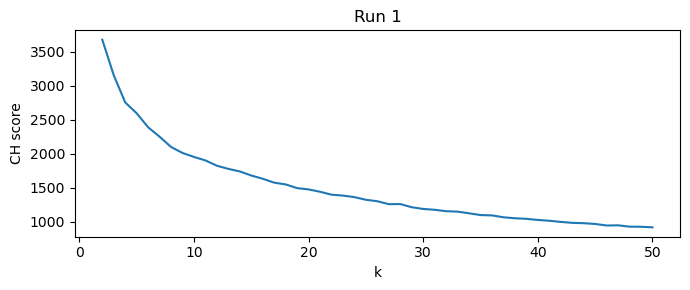

In [6]:
runs = []
first_clusters = None
first_ch = []
for run in range(50):
    best_score = -np.inf
    for k in range(2, 51):
        model = KMeans(n_clusters=k, n_init=5, random_state=run)
        clusters = model.fit_predict(x)
        score = calinski_harabasz_score(x, clusters)
        if run == 0:
            first_ch.append(score)
        if score > best_score:
            best_score = score
            best_k = k
            best_clusters = clusters.copy()
    if run == 0:
        first_clusters = best_clusters.copy()
    predicted = pd.DataFrame(index=y.index, columns=labels)
    for group in range(best_k):
        rows = best_clusters == group
        for name in labels:
            majority = y.loc[rows, name].mode().iloc[0]
            predicted.loc[rows, name] = majority
    wrong = y.to_numpy() != predicted.to_numpy()
    distance = wrong.sum(axis=1).mean()
    loss = wrong.mean()
    runs.append([run + 1, best_k, distance, 1 - loss, loss])
run_results = pd.DataFrame(runs, columns=['Run', 'k', 'Hamming distance', 'Hamming score', 'Hamming loss'])
display(run_results['k'].value_counts().sort_index().rename_axis('k').to_frame('Runs'))
plt.figure(figsize=(7, 3))
plt.plot(range(2, 51), first_ch)
plt.xlabel('k')
plt.ylabel('CH score')
plt.title('Run 1')
plt.tight_layout()
plt.show()

### (b)

Majority labels for each cluster (Run 1 shown; all 50 runs were evaluated).

In [7]:
majority_rows = []
for group in np.unique(first_clusters):
    rows = first_clusters == group
    values = [y.loc[rows, name].mode().iloc[0] for name in labels]
    majority_rows.append([group, rows.sum()] + values)
display(pd.DataFrame(majority_rows, columns=['Cluster', 'Size'] + labels))

,Cluster,Size,Family,Genus,Species
0,0,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,3597,Hylidae,Hypsiboas,HypsiboasCordobae


### (c)

In [8]:
summary = run_results[['Hamming distance', 'Hamming score', 'Hamming loss']].agg(['mean', 'std']).T
summary.columns = ['Mean', 'Standard deviation']
summary.index.name = 'Metric'
display(summary.round(6))

,Mean,Standard deviation
Metric,,
Hamming distance,0.895622,0.0
Hamming score,0.701459,0.0
Hamming loss,0.298541,0.0


CH selects k = 2 in all 50 runs. The mean Hamming distance is 0.895622 out of 3, with standard deviation 0. The mean Hamming loss is 0.298541 (about 29.85% wrong labels), and the mean Hamming score is 0.701459.

CH is undefined for k = 1, so the search starts at 2. The different random starts give the same evaluation scores. Two clusters can predict at most two label combinations, which limits recovery of the 4 families, 8 genera and 10 species.

## 3. ISLR 12.6.2

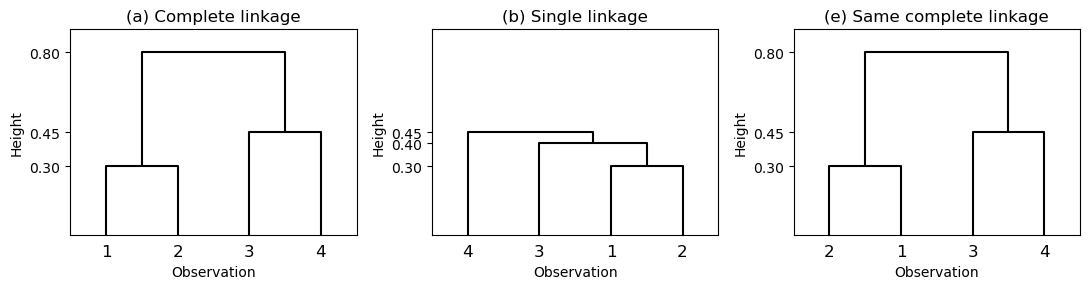

In [9]:
distance = np.array([[0, 0.3, 0.4, 0.7], [0.3, 0, 0.5, 0.8], [0.4, 0.5, 0, 0.45], [0.7, 0.8, 0.45, 0]])
complete = linkage(squareform(distance), method='complete')
single = linkage(squareform(distance), method='single')
swapped = complete.copy()
swapped[0, :2] = swapped[0, :2][::-1]
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, tree, title in zip(axes, [complete, single, swapped], ['(a) Complete linkage', '(b) Single linkage', '(e) Same complete linkage']):
    dendrogram(tree, labels=['1', '2', '3', '4'], ax=ax, color_threshold=0, above_threshold_color='black')
    heights = np.unique(tree[:, 2])
    ax.set_yticks(heights)
    ax.set_ylim(0, 0.9)
    ax.set_title(title)
    ax.set_xlabel('Observation')
    ax.set_ylabel('Height')
plt.tight_layout()
plt.show()

(a) Complete linkage merges {1, 2} at 0.30 and {3, 4} at 0.45. The two clusters merge at 0.80.

(b) Single linkage merges {1, 2} at 0.30, adds 3 at 0.40, and adds 4 at 0.45.

(c) The two clusters are {1, 2} and {3, 4}.

(d) The two clusters are {1, 2, 3} and {4}.

(e) The last plot swaps leaves 1 and 2. The merge heights and cluster memberships stay the same.